# Phase 8 - Dynamic Interaction Graph
Construct dynamic interaction graphs from real tracked road users to map vehicle-vehicle and vehicle-VRU conflicts.
**Nodes:** Tracked Sentinel objects (pedestrian, bicycle, motorcycle, vehicle).
**Edges:** Represent potential interactions, quantified by image-space proximity, relative velocity, and trajectory convergence.

*Rule Enforcement:* We only create edges from real tracked agents. We do NOT fabricate interactions. A traffic anomaly is NOT automatically a VRU conflict unless the interaction edges mathematically justify it.


In [1]:
# Environment Setup
import os
import math
import numpy as np
import pandas as pd
import networkx as nx
import pickle
import matplotlib.pyplot as plt

INPUT_KINEMATICS = '../results/calibration/image_space_kinematics.csv'
INPUT_ANOMALIES = '../data/processed/AI_City/temporal_events.csv'
OUTPUT_DIR = '../results/interaction_graphs'

os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Graph Construction Engine
Defines the mathematical logic for creating edge features (Distance, Relative Velocity, Trajectory Convergence) exclusively from available image-space kinematics.


In [2]:
def compute_edge_features(node_a, node_b):
    # node_a and node_b are pandas Series representing a track at a specific timestamp
    dx = node_b['center_x'] - node_a['center_x']
    dy = node_b['bottom_center_y'] - node_a['bottom_center_y']
    pixel_distance = math.sqrt(dx**2 + dy**2)
    
    # Relative velocity
    dv_x = node_b['vel_x_px'] - node_a['vel_x_px']
    dv_y = node_b['vel_y_px'] - node_a['vel_y_px']
    relative_velocity = math.sqrt(dv_x**2 + dv_y**2)
    
    # Trajectory convergence (Dot product of heading vectors)
    # Are they moving towards each other?
    norm_a = max(node_a['pixel_velocity_magnitude'], 1e-6)
    norm_b = max(node_b['pixel_velocity_magnitude'], 1e-6)
    
    heading_a = (node_a['vel_x_px'] / norm_a, node_a['vel_y_px'] / norm_a)
    heading_b = (node_b['vel_x_px'] / norm_b, node_b['vel_y_px'] / norm_b)
    
    convergence = heading_a[0]*heading_b[0] + heading_a[1]*heading_b[1] # -1 = opposite, 1 = parallel
    
    # Proxy TTC (Time-To-Collision in image space)
    # If moving towards each other, relative velocity > 0
    proxy_ttc = (pixel_distance / relative_velocity) if relative_velocity > 1 else 999.0
    
    return {
        'pixel_distance': pixel_distance,
        'relative_velocity': relative_velocity,
        'trajectory_convergence': convergence,
        'proxy_ttc': proxy_ttc
    }

def build_frame_graph(frame_data):
    G = nx.Graph()
    
    # Add Nodes
    for _, row in frame_data.iterrows():
        G.add_node(row['track_id'], 
                   cls=row['class'], 
                   pos=(row['center_x'], row['bottom_center_y']),
                   vel=row['pixel_velocity_magnitude'])
                   
    # Add Edges (Fully connected for all actors in frame, filtered by distance)
    node_ids = frame_data.index.tolist()
    for i in range(len(node_ids)):
        for j in range(i+1, len(node_ids)):
            n_a = frame_data.loc[node_ids[i]]
            n_b = frame_data.loc[node_ids[j]]
            
            features = compute_edge_features(n_a, n_b)
            
            # Only connect interacting agents (e.g., within 800 pixels)
            if features['pixel_distance'] < 800:
                G.add_edge(n_a['track_id'], n_b['track_id'], **features)
                
    return G


## 2. Dynamic Graph Extraction (AI City Track 4)
Build graph sequences mapping exactly to the Anomaly Pre-Onset, Interval, and Post-Anomaly periods.


In [3]:
if os.path.exists(INPUT_KINEMATICS):
    df_kin = pd.read_csv(INPUT_KINEMATICS).dropna()
    
    # Process graph per timestamp
    timestamps = sorted(df_kin['timestamp'].unique())
    
    graph_sequence = {}
    
    print(f"Building interaction graphs for {len(timestamps)} frames...")
    
    for ts in timestamps:
        frame_data = df_kin[df_kin['timestamp'] == ts]
        if len(frame_data) > 1: # Require at least 2 nodes for an interaction graph
            G = build_frame_graph(frame_data)
            graph_sequence[ts] = G
            
    # Save graph sequence
    out_path = os.path.join(OUTPUT_DIR, 'interaction_graph_sequence.pkl')
    with open(out_path, 'wb') as f:
        pickle.dump(graph_sequence, f)
        
    print(f"Saved {len(graph_sequence)} frame-graphs to {out_path}.")
else:
    print(f"Kinematics data not found at {INPUT_KINEMATICS}. Run Phase 7 first.")


Building interaction graphs for 148 frames...
Saved 148 frame-graphs to ../results/interaction_graphs\interaction_graph_sequence.pkl.


## 3. Visualize Interaction Graph
Render a snapshot of a highly connected frame to verify node classes and edge features.


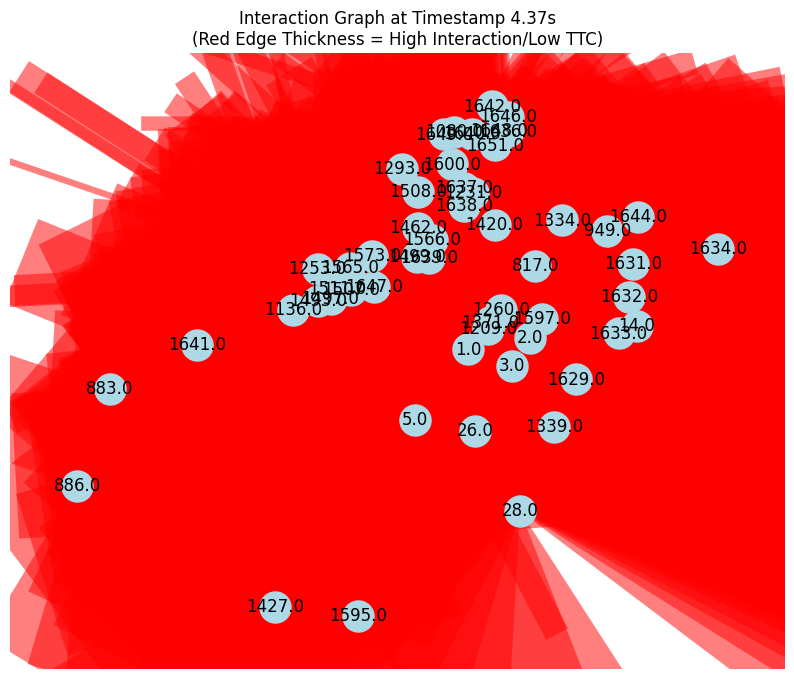

In [4]:
if 'graph_sequence' in locals() and graph_sequence:
    # Find the graph with the most edges (highest interaction density)
    max_edges_ts = max(graph_sequence.keys(), key=lambda ts: graph_sequence[ts].number_of_edges())
    G_viz = graph_sequence[max_edges_ts]
    
    plt.figure(figsize=(10, 8))
    pos = nx.get_node_attributes(G_viz, 'pos')
    
    # Invert Y axis to match image coordinates
    pos = {k: (v[0], -v[1]) for k, v in pos.items()}
    
    # Draw Nodes
    nx.draw_networkx_nodes(G_viz, pos, node_size=500, node_color='lightblue')
    nx.draw_networkx_labels(G_viz, pos)
    
    # Draw Edges (Thickness based on proximity/TTC)
    edges = G_viz.edges(data=True)
    weights = [max(1, 1000 / (e[2]['proxy_ttc'] + 1)) for e in edges]
    nx.draw_networkx_edges(G_viz, pos, width=weights, alpha=0.5, edge_color='red')
    
    plt.title(f'Interaction Graph at Timestamp {max_edges_ts:.2f}s\n(Red Edge Thickness = High Interaction/Low TTC)')
    plt.axis('off')
    plt.savefig(os.path.join(OUTPUT_DIR, 'interaction_graph_sample.png'))
    plt.show()
